In [ ]:
!pip install nltk

In [ ]:
import nltk,warnings
warnings.filterwarnings('ignore')
for pkg in ['punk_tab', 'stopwords', 'wordnet', 'movie_reviews']:
  nltk.download(pkg,quiet=True)
print('NLP environtment ready!')

[nltk_data] Error loading punk_tab: Package 'punk_tab' not found in
[nltk_data]     index


NLP environtment ready!


In [ ]:
corpus = ["My Name is . Akshaya . Tanwar.",
          "I am a Data Science Student.",
          "Currently in 5th Sem.",
          "KRMU",
          ]
with open('corpus.txt', 'w') as f:
  f.write('\n'.join(corpus))
  print('corpus.txt written:', len(corpus), 'documents')

corpus.txt written: 4 documents


In [ ]:
import nltk
nltk.download('punkt_tab')


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
from nltk.tokenize import word_tokenize, sent_tokenize
docs = open('corpus.txt').read().splitlines()
text = ' '.join(docs)
sents = sent_tokenize(text)
words = word_tokenize(text)
print('documents :', len(docs))
print('sentences :', len(sents))
print('words(tokens) :', len(words))
print('unique tokens :', len(set(w.lower()for w in words)))
print('Average words per document :', round(len(words)/len(docs), 1))
print("token", words)

documents : 4
sentences : 6
words(tokens) : 21
unique tokens : 17
Average words per document : 5.2
token ['My', 'Name', 'is', '.', 'Akshaya', '.', 'Tanwar', '.', 'I', 'am', 'a', 'Data', 'Science', 'Student', '.', 'Currently', 'in', '5th', 'Sem', '.', 'KRMU']


In [ ]:
print(docs)

['My Name is . Akshaya . Tanwar.', 'I am a Data Science Student.', 'Currently in 5th Sem.', 'KRMU']


In [ ]:
sample = docs[0]
print('Raw text:', sample)
print('word tokens:', word_tokenize(sample))
print('sentence tokens:', sent_tokenize(sample))
print('naive split():', sample.split()[:6], '...')

Raw text: My Name is . Akshaya . Tanwar.
word tokens: ['My', 'Name', 'is', '.', 'Akshaya', '.', 'Tanwar', '.']
sentence tokens: ['My Name is .', 'Akshaya .', 'Tanwar.']
naive split(): ['My', 'Name', 'is', '.', 'Akshaya', '.'] ...


In [ ]:
import nltk,warnings
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [ ]:
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
ps, ss, lem = PorterStemmer(), SnowballStemmer('english'), WordNetLemmatizer()
Words3 = ['running', 'studies', 'better', 'flies', 'meeting', 'dissapointing']
print(f"{'word':<15}{'Porter':<12}{'Snowball':<12}{'Lemma (v)':<12}")
for w in Words3:
  print(f"{w:<15}{ps.stem(w):<12}{ss.stem(w):<12}{lem.lemmatize(w, pos='v'):<12}")

word           Porter      Snowball    Lemma (v)   
running        run         run         run         
studies        studi       studi       study       
better         better      better      better      
flies          fli         fli         fly         
meeting        meet        meet        meet        
dissapointing  dissapoint  dissapoint  dissapointing


In [ ]:
from nltk. corpus import stopwords
import string
stop = set(stopwords. words('english'))
toks = word_tokenize(' '.join(docs).lower())
clean = [t for t in toks if t not in stop and t not in string.punctuation]
print('before:', len(toks), 'tokens | after:', len(clean), 'tokens')
print('first 15 cleaned tokens:', clean[:15])

before: 21 tokens | after: 10 tokens
first 15 cleaned tokens: ['name', 'akshaya', 'tanwar', 'data', 'science', 'student', 'currently', '5th', 'sem', 'krmu']


In [ ]:
import re
def clean_text(t):
  t = re.sub(r'http\S+', '', t)
  t = re.sub(r'@\w+', '', t)
  t = re.sub(r'\d+', '', t)
  t = re.sub(r'[^A-Za-z\s]', '', t)
  return re.sub(r'\s+', '', t).strip()
print('Before:', docs[1])
print('After:', clean_text(docs[1]))

Before: I am a Data Science Student.
After: IamaDataScienceStudent


10 most common words:
 name         1
 akshaya      1
 tanwar       1
 data         1
 science      1
 student      1
 currently    1
 5th          1
 sem          1
 krmu         1
Hapaxes (first 8): ['name', 'akshaya', 'tanwar', 'data', 'science', 'student', 'currently', '5th']


<Axes: title={'center': 'Top-20 Word Frequencies'}, xlabel='Samples', ylabel='Counts'>

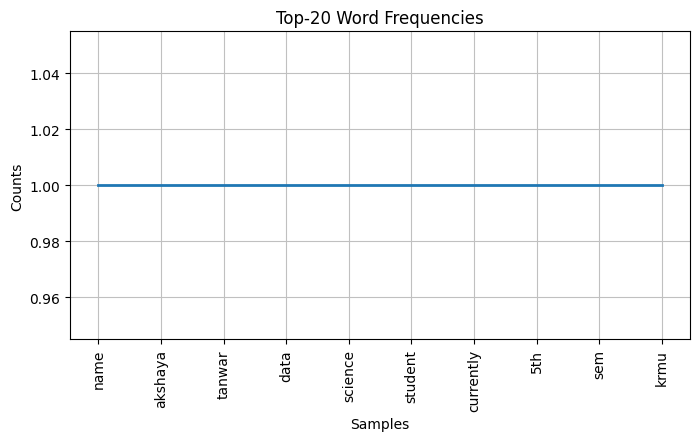

In [ ]:
%matplotlib inline
from nltk import FreqDist
import matplotlib.pyplot as plt
fd = FreqDist(clean)
print('10 most common words:')
for w, cnt in fd.most_common(10):
  print(f' {w:<12} {cnt}')
print('Hapaxes (first 8):', fd.hapaxes() [:8])
plt.figure(figsize=(8,4))
fd.plot(20,title='Top-20 Word Frequencies')